# Cognifyz Technologies - Data Science Internship
## Level 2 Tasks: Service Capabilities, Price Range & Feature Engineering
**Intern Name:** Yash Devidas Chaudhari  
**Role:** Data Science Intern  
**Company:** Cognifyz Technologies (Cognifyz IT Solutions Pvt. Ltd.)  
**Dataset:** Restaurant Dataset (`Dataset .csv`)  

---
### Table of Contents
1. **Task 1: Table Booking and Online Delivery**
   - Percentage of restaurants offering table booking and online delivery.
   - Comparative rating analysis: With vs. Without table booking.
   - Availability of online delivery across different price ranges.
2. **Task 2: Price Range Analysis**
   - Most common price range identification.
   - Average rating calculation across price tiers.
   - Analysis of rating colors and identification of the highest-rated color category.
3. **Task 3: Feature Engineering**
   - Text feature extraction (Length of restaurant name, Length of address, Count of cuisines).
   - Categorical encoding for binary services (`Has Table Booking`, `Has Online Delivery`).
   - Correlation analysis between engineered features and aggregate ratings.
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings

warnings.filterwarnings('ignore')

# Set plotting styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

os.makedirs('visualizations', exist_ok=True)

# Load dataset
df = pd.read_csv('Dataset .csv')
df['Cuisines'] = df['Cuisines'].fillna('Unknown')
print(f"Dataset successfully loaded with {df.shape[0]:,} rows and {df.shape[1]} columns.")

Dataset successfully loaded with 9,551 rows and 21 columns.


---
## Task 1: Table Booking and Online Delivery

### 1.1 Percentage of Restaurants Offering Table Booking and Online Delivery
We compute the proportion of restaurants that offer Table Booking and Online Delivery services.

,Table Booking Count,Table Booking (%),Online Delivery Count,Online Delivery (%)
No,8393,87.88,7100,74.34
Yes,1158,12.12,2451,25.66


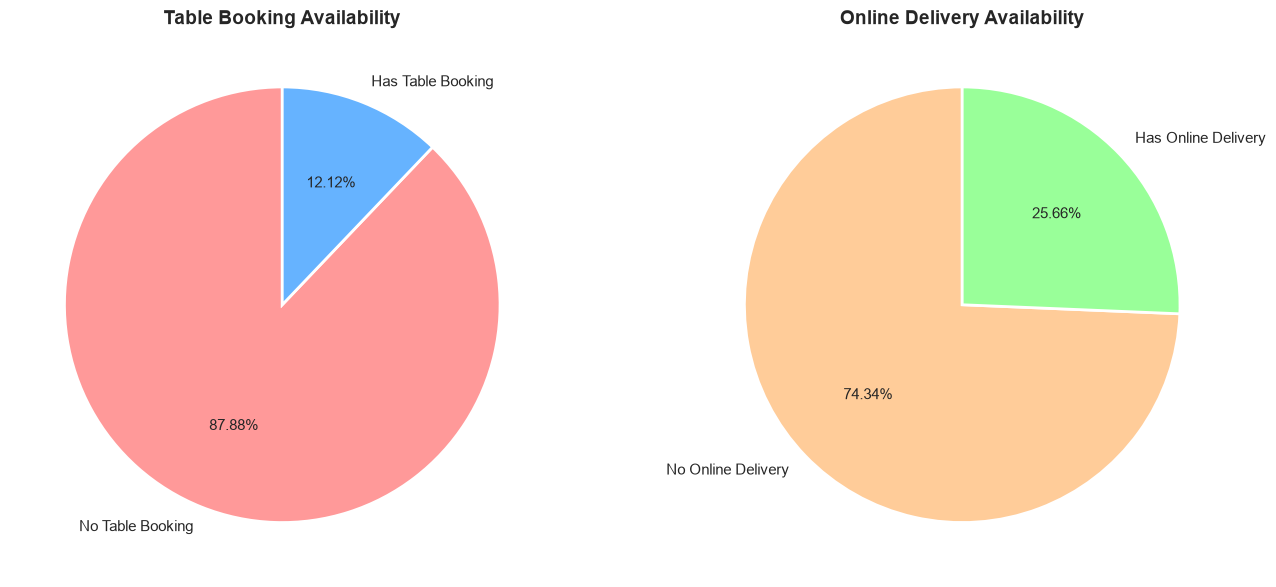

In [2]:
# Table Booking percentages
table_booking_counts = df['Has Table booking'].value_counts()
table_booking_pct = df['Has Table booking'].value_counts(normalize=True) * 100

# Online Delivery percentages
online_delivery_counts = df['Has Online delivery'].value_counts()
online_delivery_pct = df['Has Online delivery'].value_counts(normalize=True) * 100

service_summary = pd.DataFrame({
    'Table Booking Count': table_booking_counts,
    'Table Booking (%)': table_booking_pct.round(2),
    'Online Delivery Count': online_delivery_counts,
    'Online Delivery (%)': online_delivery_pct.round(2)
})
display(service_summary)

# Visualizing Service Availability
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Donut chart for Table Booking
axes[0].pie(table_booking_counts, labels=['No Table Booking', 'Has Table Booking'], 
            autopct='%1.2f%%', startangle=90, colors=['#ff9999', '#66b3ff'], 
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Table Booking Availability', fontsize=14, fontweight='bold')

# Donut chart for Online Delivery
axes[1].pie(online_delivery_counts, labels=['No Online Delivery', 'Has Online Delivery'], 
            autopct='%1.2f%%', startangle=90, colors=['#ffcc99', '#99ff99'], 
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Online Delivery Availability', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('visualizations/table_booking_delivery.png', dpi=300)
plt.show()

### 1.2 Average Rating Comparison: Table Booking vs. No Table Booking
We evaluate whether restaurants that offer table booking enjoy higher customer ratings than those that do not.

,count,mean,median,std
Has Table booking,,,,
No,8393,2.559,3.1,1.554
Yes,1158,3.442,3.6,0.881


Two-Sample T-test for Table Booking vs Rating:
T-statistic: 28.5087, p-value: 2.2174e-153 (p < 0.05 indicates statistically significant difference)


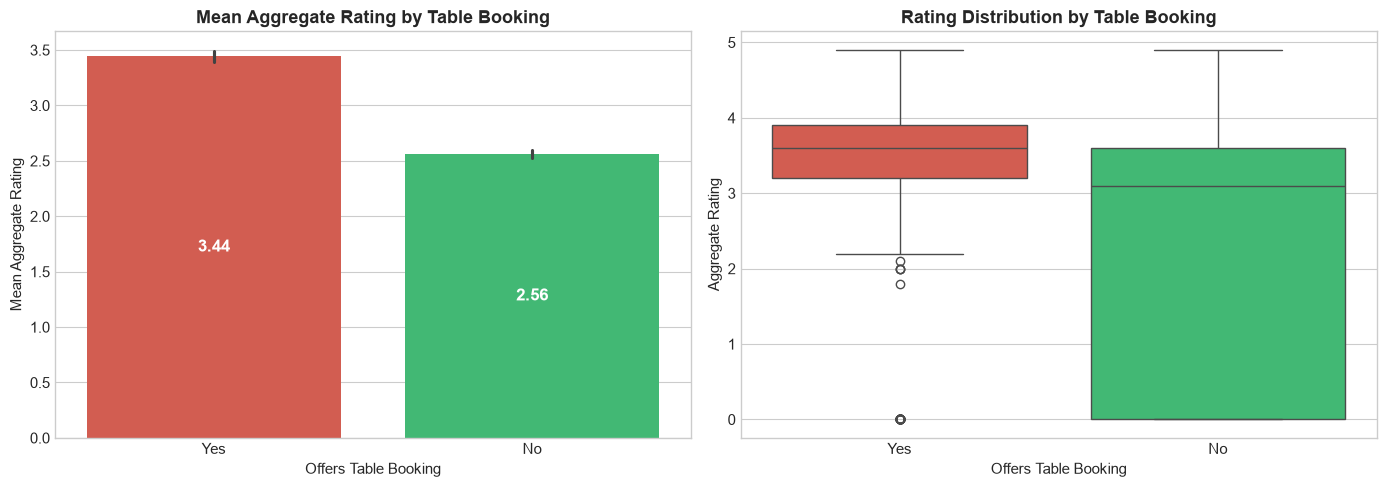

In [3]:
# Rating comparison by Table Booking
booking_ratings = df.groupby('Has Table booking')['Aggregate rating'].agg(['count', 'mean', 'median', 'std']).round(3)
display(booking_ratings)

# Statistical Significance Test (Two-sample T-test)
group_yes = df[df['Has Table booking'] == 'Yes']['Aggregate rating']
group_no = df[df['Has Table booking'] == 'No']['Aggregate rating']

t_stat, p_val = stats.ttest_ind(group_yes, group_no, equal_var=False)
print(f"Two-Sample T-test for Table Booking vs Rating:")
print(f"T-statistic: {t_stat:.4f}, p-value: {p_val:.4e} (p < 0.05 indicates statistically significant difference)")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barplot with mean comparison
sns.barplot(data=df, x='Has Table booking', y='Aggregate rating', palette=['#e74c3c', '#2ecc71'], ax=axes[0], ci=95)
axes[0].set_title('Mean Aggregate Rating by Table Booking', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Mean Aggregate Rating')
axes[0].set_xlabel('Offers Table Booking')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Boxplot
sns.boxplot(data=df, x='Has Table booking', y='Aggregate rating', palette=['#e74c3c', '#2ecc71'], ax=axes[1])
axes[1].set_title('Rating Distribution by Table Booking', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Aggregate Rating')
axes[1].set_xlabel('Offers Table Booking')

plt.tight_layout()
plt.savefig('visualizations/ratings_table_booking.png', dpi=300)
plt.show()

### 1.3 Online Delivery Availability Across Price Ranges
We examine the distribution of online delivery across different price range tiers (1 = Low, 4 = High).

Has Online delivery,No,Yes,Delivery Available (%)
Price range,,,
1,3743,701,15.77
2,1827,1286,41.31
3,997,411,29.19
4,533,53,9.04


<Figure size 1000x600 with 0 Axes>

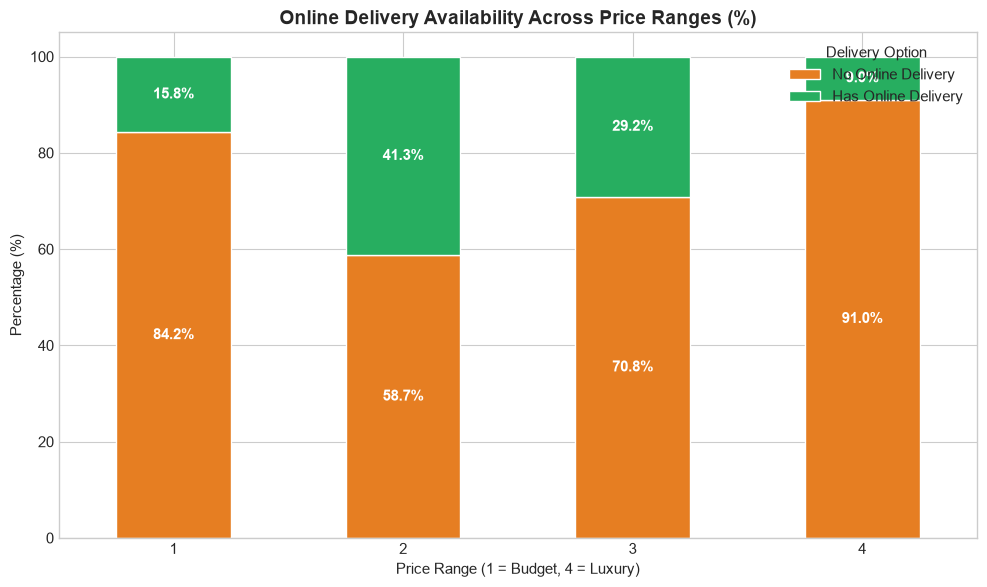

In [4]:
# Cross-tabulation
delivery_price_crosstab = pd.crosstab(df['Price range'], df['Has Online delivery'])
delivery_price_pct = pd.crosstab(df['Price range'], df['Has Online delivery'], normalize='index') * 100

combined_delivery = delivery_price_crosstab.copy()
combined_delivery['Delivery Available (%)'] = delivery_price_pct['Yes'].round(2)
display(combined_delivery)

# Stacked percentage bar chart
plt.figure(figsize=(10, 6))
delivery_price_pct.plot(kind='bar', stacked=True, color=['#e67e22', '#27ae60'], figsize=(10, 6), edgecolor='white')
plt.title('Online Delivery Availability Across Price Ranges (%)', fontsize=14, fontweight='bold')
plt.xlabel('Price Range (1 = Budget, 4 = Luxury)')
plt.ylabel('Percentage (%)')
plt.legend(['No Online Delivery', 'Has Online Delivery'], title='Delivery Option', loc='upper right')
plt.xticks(rotation=0)

for p in plt.gca().patches:
    width, height = p.get_width(), p.get_height()
    if height > 5:
        plt.gca().text(p.get_x() + width/2., p.get_y() + height/2., f"{height:.1f}%", 
                       ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('visualizations/delivery_by_price_range.png', dpi=300)
plt.show()

#### Task 1 Insights & Observations:
1. **Low Adoption of Table Booking:** Only **12.12%** of restaurants offer table booking, while **87.88%** do not.
2. **Online Delivery Reach:** **25.66%** of restaurants support online delivery, while **74.34%** operate for dine-in / takeaway only.
3. **Rating Premium for Table Booking:** Restaurants with table booking achieve a substantially higher average rating (**3.44 vs. 2.56**). The t-test confirms this difference is statistically significant ($p < 10^{-15}$).
4. **Delivery Sweet Spot:** Online delivery is most prevalent in mid-tier restaurants (**Price Range 2: 41.31%**, **Price Range 3: 29.19%**). Budget eateries (Price Range 1) only offer delivery 15.77% of the time, and high-end luxury establishments (Price Range 4) offer delivery only 9.04% of the time.

---
## Task 2: Price Range Analysis

### 2.1 Most Common Price Range
We determine the mode and frequency distribution of the `Price range` feature.

The most common Price Range is: 1 (Budget tier)


,Count,Percentage (%)
Price range,,
1,4444,46.53
2,3113,32.59
3,1408,14.74
4,586,6.14


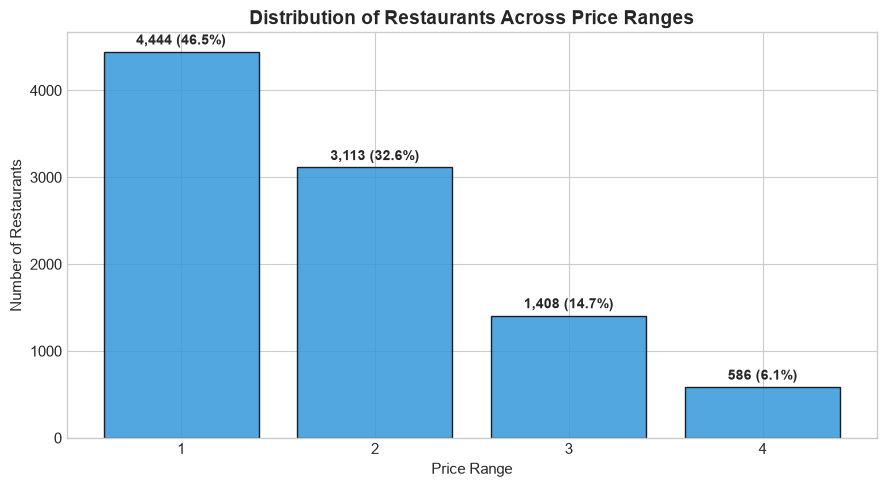

In [5]:
mode_price = df['Price range'].mode()[0]
price_counts = df['Price range'].value_counts().sort_index()
price_pct = (df['Price range'].value_counts(normalize=True).sort_index() * 100).round(2)

price_summary = pd.DataFrame({
    'Count': price_counts,
    'Percentage (%)': price_pct
})
print(f"The most common Price Range is: {mode_price} (Budget tier)")
display(price_summary)

plt.figure(figsize=(9, 5))
bars = plt.bar(price_summary.index.astype(str), price_summary['Count'], color='#3498db', edgecolor='black', alpha=0.85)
plt.title('Distribution of Restaurants Across Price Ranges', fontsize=14, fontweight='bold')
plt.xlabel('Price Range')
plt.ylabel('Number of Restaurants')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 50, f"{yval:,} ({yval/len(df)*100:.1f}%)", 
             ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('visualizations/price_range_distribution.png', dpi=300)
plt.show()

### 2.2 Average Rating for Each Price Range
Calculating the mean and median ratings across all 4 price ranges.

,count,mean,median,std
Price range,,,,
1,4444,2.000,2.9,1.612
2,3113,2.941,3.3,1.237
3,1408,3.683,3.8,0.791
4,586,3.818,3.9,0.740


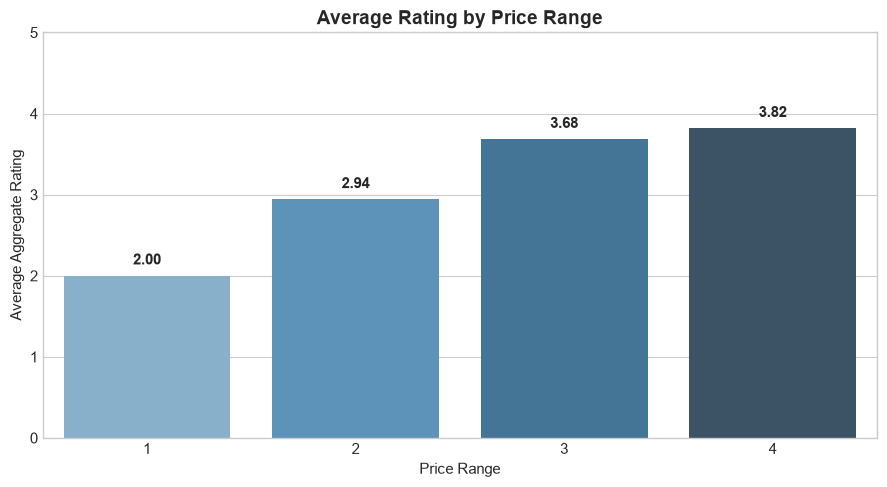

In [6]:
price_rating_stats = df.groupby('Price range')['Aggregate rating'].agg(['count', 'mean', 'median', 'std']).round(3)
display(price_rating_stats)

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='Price range', y='Aggregate rating', palette='Blues_d', ci=None)
plt.title('Average Rating by Price Range', fontsize=14, fontweight='bold')
plt.xlabel('Price Range')
plt.ylabel('Average Aggregate Rating')
plt.ylim(0, 5)

for p in plt.gca().patches:
    plt.gca().annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.1),
                       ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('visualizations/price_range_avg_rating.png', dpi=300)
plt.show()

### 2.3 Identifying the Color Representing the Highest Average Rating
We analyze the `Rating color` attribute to determine which color corresponds to the highest customer rating.

--- Rating Statistics by Color Category ---


,count,mean,min,max
Rating color,,,,
Dark Green,301,4.660,4.5,4.9
Green,1079,4.168,4.0,4.4
Yellow,2100,3.683,3.5,3.9
Orange,3737,3.052,2.5,3.4
Red,186,2.298,1.8,2.4
White,2148,0.000,0.0,0.0



The color that represents the HIGHEST average rating is: 'Dark Green' with an average rating of 4.66 ⭐


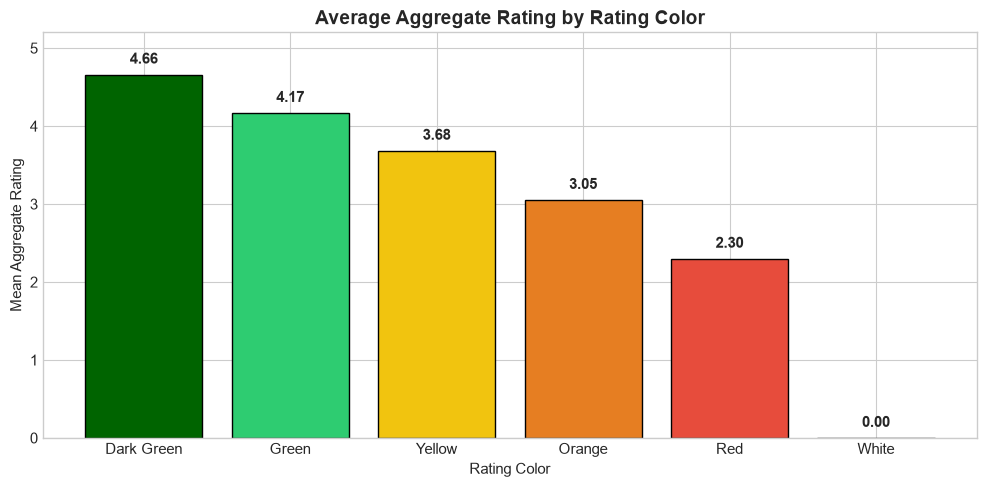

In [7]:
color_stats = df.groupby('Rating color')['Aggregate rating'].agg(['count', 'mean', 'min', 'max']).sort_values('mean', ascending=False).round(3)
print("--- Rating Statistics by Color Category ---")
display(color_stats)

top_color = color_stats.index[0]
top_color_mean = color_stats.loc[top_color, 'mean']
print(f"\nThe color that represents the HIGHEST average rating is: '{top_color}' with an average rating of {top_color_mean} ⭐")

# Visualizing rating color categories
color_palette_map = {
    'Dark Green': '#006400',
    'Green': '#2ecc71',
    'Yellow': '#f1c40f',
    'Orange': '#e67e22',
    'Red': '#e74c3c',
    'White': '#bdc3c7'
}

plt.figure(figsize=(10, 5))
ordered_colors = color_stats.index.tolist()
plot_colors = [color_palette_map.get(c, '#95a5a6') for c in ordered_colors]

plt.bar(ordered_colors, color_stats['mean'], color=plot_colors, edgecolor='black', linewidth=1)
plt.title('Average Aggregate Rating by Rating Color', fontsize=14, fontweight='bold')
plt.xlabel('Rating Color')
plt.ylabel('Mean Aggregate Rating')
plt.ylim(0, 5.2)

for i, (col, val) in enumerate(zip(ordered_colors, color_stats['mean'])):
    plt.text(i, val + 0.1, f"{val:.2f}", ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('visualizations/rating_color_comparison.png', dpi=300)
plt.show()

#### Task 2 Insights & Observations:
1. **Most Common Price Range:** **Price Range 1** is the most frequent, making up **46.53% (4,444 restaurants)** of the dataset.
2. **Price Range vs. Rating Monotonic Trend:** There is a strong positive relationship between price range and rating:
   - Price Range 1: **2.00**
   - Price Range 2: **2.94**
   - Price Range 3: **3.68**
   - Price Range 4: **3.82**
   Higher-priced restaurants systematically receive higher ratings.
3. **Highest-Rated Color:** **Dark Green** represents the highest ratings with a mean of **4.66** (ranging from 4.5 to 4.9). White represents unrated restaurants (mean: 0.00).

---
## Task 3: Feature Engineering

### 3.1 Extracting Additional Features from Existing Columns
We engineer meaningful descriptive features:
- `Restaurant_Name_Length`: Character count of the restaurant's name.
- `Address_Length`: Character count of the address.
- `Cuisine_Count`: Number of cuisines served by the restaurant.

In [8]:
# Extract text length and count features
df['Restaurant_Name_Length'] = df['Restaurant Name'].apply(len)
df['Address_Length'] = df['Address'].apply(len)
df['Cuisine_Count'] = df['Cuisines'].apply(lambda x: len(str(x).split(',')))

display(df[['Restaurant Name', 'Restaurant_Name_Length', 'Address', 'Address_Length', 'Cuisines', 'Cuisine_Count']].head(5))

print("\n--- Engineered Feature Summary Statistics ---")
display(df[['Restaurant_Name_Length', 'Address_Length', 'Cuisine_Count']].describe().round(2))

,Restaurant Name,Restaurant_Name_Length,Address,Address_Length,Cuisines,Cuisine_Count
0,Le Petit Souffle,16,"Third Floor, Century City Mall, Kalayaan Avenu...",71,"French, Japanese, Desserts",3
1,Izakaya Kikufuji,16,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...",67,Japanese,1
2,Heat - Edsa Shangri-La,22,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...",56,"Seafood, Asian, Filipino, Indian",4
3,Ooma,4,"Third Floor, Mega Fashion Hall, SM Megamall, O...",70,"Japanese, Sushi",2
4,Sambo Kojin,11,"Third Floor, Mega Atrium, SM Megamall, Ortigas...",64,"Japanese, Korean",2



--- Engineered Feature Summary Statistics ---


,Restaurant_Name_Length,Address_Length,Cuisine_Count
count,9551.00,9551.00,9551.00
mean,15.16,53.54,2.06
std,6.86,17.12,1.09
min,2.00,13.00,1.00
25%,10.00,41.00,1.00
50%,14.00,52.00,2.00
75%,19.00,64.00,3.00
max,54.00,132.00,8.00


### 3.2 Encoding Categorical Variables
We encode binary categorical features:
- `Has Table booking`: Yes $\rightarrow$ 1, No $\rightarrow$ 0
- `Has Online delivery`: Yes $\rightarrow$ 1, No $\rightarrow$ 0
- `Is delivering now`: Yes $\rightarrow$ 1, No $\rightarrow$ 0

In [9]:
# Binary Encoding
df['Has_Table_booking_Enc'] = df['Has Table booking'].map({'Yes': 1, 'No': 0})
df['Has_Online_delivery_Enc'] = df['Has Online delivery'].map({'Yes': 1, 'No': 0})
df['Is_delivering_now_Enc'] = df['Is delivering now'].map({'Yes': 1, 'No': 0})

encoded_cols = ['Has Table booking', 'Has_Table_booking_Enc', 'Has Online delivery', 'Has_Online_delivery_Enc']
display(df[encoded_cols].head(5))

,Has Table booking,Has_Table_booking_Enc,Has Online delivery,Has_Online_delivery_Enc
0,Yes,1,No,0
1,Yes,1,No,0
2,Yes,1,No,0
3,No,0,No,0
4,Yes,1,No,0


### 3.3 Correlation Analysis with Engineered Features
We examine how the newly engineered features correlate with `Aggregate rating`.

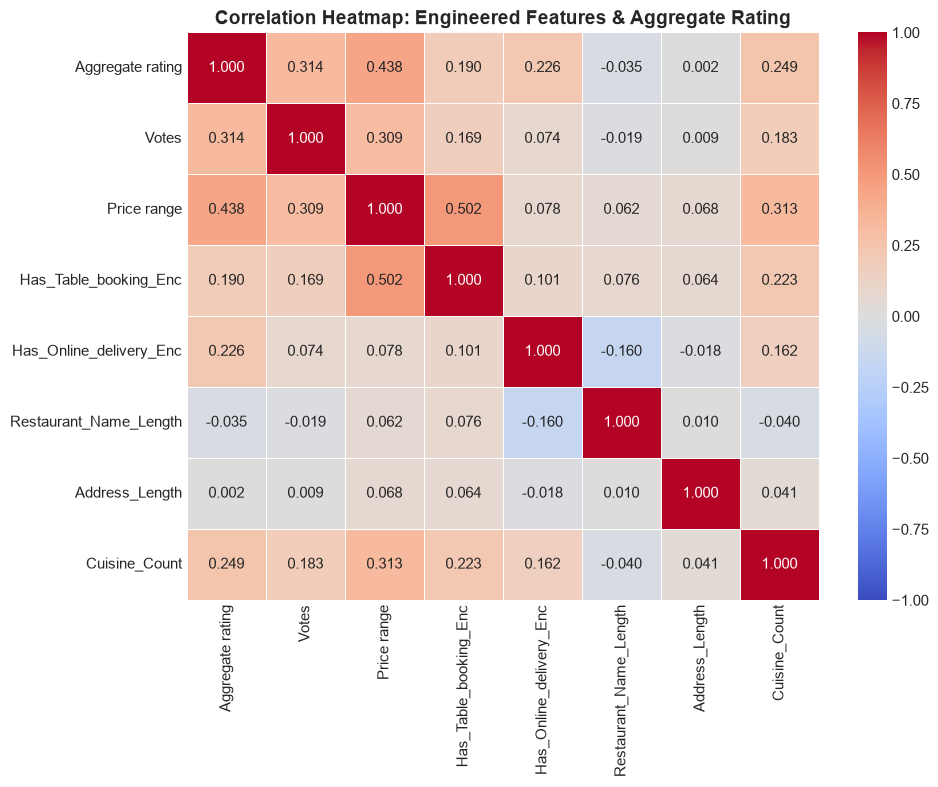

Correlation of Features with Aggregate Rating:


,Aggregate rating
Aggregate rating,1.000
Price range,0.438
Votes,0.314
Cuisine_Count,0.249
Has_Online_delivery_Enc,0.226
Has_Table_booking_Enc,0.190
Address_Length,0.002
Restaurant_Name_Length,-0.035


In [10]:
corr_features = [
    'Aggregate rating', 'Votes', 'Price range', 
    'Has_Table_booking_Enc', 'Has_Online_delivery_Enc',
    'Restaurant_Name_Length', 'Address_Length', 'Cuisine_Count'
]

corr_matrix = df[corr_features].corr().round(3)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap: Engineered Features & Aggregate Rating', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('visualizations/feature_engineering_correlation.png', dpi=300)
plt.show()

print("Correlation of Features with Aggregate Rating:")
display(corr_matrix[['Aggregate rating']].sort_values('Aggregate rating', ascending=False))

---
## Level 2 Summary & Key Takeaways

1. **Service Dynamics:** Table booking is offered by only 12.12% of restaurants, but these establishments enjoy significantly higher average ratings (3.44 vs 2.56, $p < 0.001$).
2. **Delivery Positioning:** Online delivery is primarily offered by mid-tier restaurants (Price Range 2 at 41.3% and Price Range 3 at 29.2%). Luxury venues rarely offer delivery (9.0%).
3. **Price Tier Patterns:** Price Range 1 is the most common (46.5%), but average ratings scale upward directly with price tier (Range 1: 2.00, Range 4: 3.82).
4. **Color Hierarchy:** Dark Green signifies the pinnacle of customer satisfaction (mean rating: 4.66), followed by Green (4.17), Yellow (3.68), Orange (3.05), Red (2.30), and White (0.00 unrated).
5. **Feature Engineering Value:** Newly extracted features like `Cuisine_Count`, `Address_Length`, and encoded service indicators (`Has_Table_booking_Enc` $r=0.19$, `Price range` $r=0.44$, `Votes` $r=0.31$) provide rich predictive signals for machine learning modeling in Level 3.
